# Notebook 02 — Identity Encoding Analysis and Non-Neural Baselines

**Track A · Soccer Event Transformer · Identity × Context project**

| Item | Content |
|---|---|
| **Research question (project level)** | When identity and context point to different actions, what does a trained model do? Track A trains and freezes that model. |
| **Purpose of this notebook** | (1) Measure, on the training split only, how many players can receive a dedicated identity vector under the 100-event and 300-event rules, and build the three player encodings used later (T100, T300, T100-shuffled). (2) Define the evaluation metrics. (3) Fit simple non-neural baselines that set the performance floor the Transformer must beat. |
| **Scientific decisions made here** | Player vocabularies are built from training counts only. The shuffled control is defined. No model is selected here: the predictive comparison of T100, T300 and T100-shuffled is made in notebook 05, once the Transformer exists. |
| **Test data** | Not used. All results in this notebook are on the validation split. |

**Order of the analysis.** The *statistics* of the thresholds are computed here, but the *model comparison* T100 vs T300 vs T100-shuffled requires a trained Transformer and is therefore carried out in notebook 05.

Authored by: Alisha Shaikh (PICT, Pune)

In [1]:
# ---------------------------------------------------------------------------
# Environment setup (identical at the top of every Track A notebook)
# ---------------------------------------------------------------------------
import os
import sys
import json
import time
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# PROJECT_DIR holds code (src/), data artifacts, runs, results and the release.
PROJECT_DIR = Path(os.environ.get("TRACK_A_DIR", "/content/drive/MyDrive/soccer_mi/track_a"))
# DATASET_PATH is the prepared research dataset (one row per on-ball event).
DATASET_PATH = Path(os.environ.get("TRACK_A_DATASET", str(PROJECT_DIR / "data" / "cleaned_dataset.parquet")))
# RUN_MODE = "full"  -> real research runs (use this for every reported number)
# RUN_MODE = "smoke" -> tiny code check only; outputs go to PROJECT_DIR/smoke and are NOT results
RUN_MODE = os.environ.get("TRACK_A_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
(PROJECT_DIR / "src").mkdir(exist_ok=True)
(PROJECT_DIR / "tests").mkdir(exist_ok=True)

# Data-audit artifacts are cheap and always produced in full mode.
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
# Training runs, results and figures are separated by run mode so a smoke check can never
# overwrite or be confused with a research result.
OUTPUT_DIR = PROJECT_DIR if RUN_MODE == "full" else PROJECT_DIR / "smoke"
RUNS_DIR = OUTPUT_DIR / "runs"
RESULTS_DIR = OUTPUT_DIR / "results"
FIGURES_DIR = OUTPUT_DIR / "figures"
for folder in [ARTIFACTS_DIR, RUNS_DIR, RESULTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("PROJECT_DIR:", PROJECT_DIR)
print("DATASET_PATH:", DATASET_PATH, "| exists:", DATASET_PATH.exists())

Mounted at /content/drive
Colab: True | RUN_MODE: full
PROJECT_DIR: /content/drive/MyDrive/soccer_mi/track_a
DATASET_PATH: /content/drive/MyDrive/soccer_mi/track_a/data/cleaned_dataset.parquet | exists: True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib
import src.data as data
importlib.reload(data)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

events = pd.read_parquet(ARTIFACTS_DIR / "events_prepared.parquet")
print("Events:", len(events))

Events: 658905


## 1. Terms introduced in this notebook

| Term | Meaning |
|---|---|
| **Embedding** | A learned vector (here 128 numbers) looked up from a table by an integer index. The model adjusts these numbers during training so that similar inputs end up with useful vectors. |
| **Player identity embedding** | One learned 128-number vector per player. It is added to the input of every event that player performs. It can only learn something if the player appears often enough in training. |
| **Fallback index 0** | Players below the threshold, and players never seen in training, all map to index 0. Index 0 is a **fixed vector of zeros that is never trained**. Adding zeros changes nothing, so for these events the model has no player-specific information and must rely on team, role and context. Because it is never trained, index 0 cannot absorb a hidden "rare player" meaning that could be mistaken for a real player. |
| **Qualifying observation** | One event in the **training split** performed by the player. Validation and test events are never counted. |
| **T100** | A player receives a dedicated embedding if they have **at least 100** training events. |
| **T300** | A player receives a dedicated embedding if they have **at least 300** training events. |
| **Band 100–299** | Players with 100–299 training events: dedicated under T100, index 0 under T300. The T100 vs T300 comparison is decided on their events. |
| **T100-shuffled** | The T100 encoding, except that for players in the 100–299 band the player index is **randomly permuted among the band events that share the same split and role**. Each dedicated vector then receives events from a random mix of band players with that role. The number of dedicated vectors and the number of events using each vector are identical to T100, but the link to *which* player acted is destroyed. (Section 4.1 explains why the cell is split × role rather than split × role × team.) |
| **Why a shuffled control?** | If T100 beats T300, it could be because (a) the extra vectors carry player-specific information, or merely because (b) more events get *some* vector and the model has more parameters. T100-shuffled has (b) but not (a). Only if T100 also beats T100-shuffled is the gain attributable to player-specific information. |
| **Parameter count** | The number of trainable numbers in the model. Each dedicated player adds 128 parameters. |

## 2. Player frequency in the training split

**What this step does.** Counts training events per player. Every later threshold decision uses only these counts.

Distinct players in the whole dataset: 4473
Distinct players in the training split: 4061
Training events per player: median 83 | mean 129.5 | max 5630


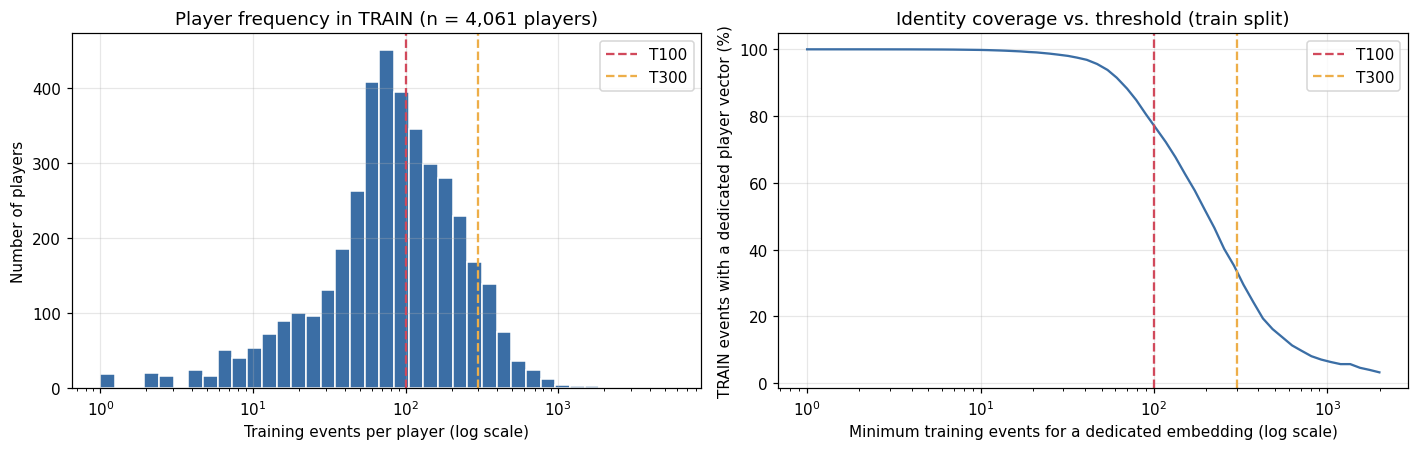

In [3]:
train_counts = events.loc[events["split"] == "train", "player_id"].value_counts()
all_players = events["player_id"].nunique()
print("Distinct players in the whole dataset:", all_players)
print("Distinct players in the training split:", len(train_counts))
print("Training events per player: median", int(train_counts.median()),
      "| mean", round(train_counts.mean(), 1), "| max", int(train_counts.max()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.logspace(0, np.log10(train_counts.max() + 1), 40)
axes[0].hist(train_counts.values, bins=bins, color="#3b6ea5", edgecolor="white")
axes[0].set_xscale("log")
axes[0].set_xlabel("Training events per player (log scale)")
axes[0].set_ylabel("Number of players")
axes[0].set_title(f"Player frequency in TRAIN (n = {len(train_counts):,} players)")
for threshold, colour in [(100, "#d1495b"), (300, "#edae49")]:
    axes[0].axvline(threshold, color=colour, linestyle="--", label=f"T{threshold}")
axes[0].legend()

thresholds_curve = np.unique(np.logspace(0, 3.3, 60).astype(int))
covered_share = []
for threshold in thresholds_curve:
    covered_share.append(100 * train_counts[train_counts >= threshold].sum() / train_counts.sum())
axes[1].plot(thresholds_curve, covered_share, color="#3b6ea5")
axes[1].set_xscale("log")
axes[1].set_xlabel("Minimum training events for a dedicated embedding (log scale)")
axes[1].set_ylabel("TRAIN events with a dedicated player vector (%)")
axes[1].set_title("Identity coverage vs. threshold (train split)")
for threshold, colour in [(100, "#d1495b"), (300, "#edae49")]:
    axes[1].axvline(threshold, color=colour, linestyle="--", label=f"T{threshold}")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_player_frequency_and_coverage.png", bbox_inches="tight")
plt.show()

**What the figure shows.** Left: how many players have a given number of training events (both axes spread over orders of magnitude). Right: the share of training events whose player would receive a dedicated vector, as the threshold increases.

**Purpose of the figure.** It shows the trade-off directly: a lower threshold covers more events but gives each vector fewer examples to learn from.

**What it shows.** Most players have few training events (a long tail of substitutes and players from few matches), while a small group of regulars accounts for most events. Coverage falls steeply as the threshold rises from 100 to 300.

**What it means.** The choice of threshold decides for how many events identity is even *available* to the model.

**What cannot be concluded.** Coverage is not usefulness. A vector trained on 100 events may be too noisy to help; that is tested in notebook 05.

## 3. Exact threshold table (train-derived, reported for every split)

For each threshold the table reports how many players receive a dedicated embedding and what share of **train, validation and test** events keep a dedicated identity. Held-out coverage is lower than train coverage because players unseen in training, or seen fewer times than the threshold, map to index 0. That gap is reported, not corrected.

In [4]:
EMBEDDING_WIDTH = 128   # d_model of the planned Transformer
threshold_rows = []
for threshold in [50, 100, 200, 300, 500, 1000]:
    dedicated_players = set(train_counts[train_counts >= threshold].index)
    row = {"threshold": threshold,
           "unique players (train)": len(train_counts),
           "dedicated embeddings": len(dedicated_players),
           "players mapped to index 0 (train)": len(train_counts) - len(dedicated_players)}
    for split_name in ["train", "val", "test"]:
        split_players = events.loc[events["split"] == split_name, "player_id"]
        has_identity = split_players.isin(dedicated_players)
        row[f"{split_name} % dedicated"] = round(100 * has_identity.mean(), 2)
        row[f"{split_name} % index 0"] = round(100 * (1 - has_identity.mean()), 2)
        row[f"{split_name} events on index 0"] = int((~has_identity).sum())
    row["player-embedding parameters"] = (len(dedicated_players) + 1) * EMBEDDING_WIDTH
    threshold_rows.append(row)
threshold_table = pd.DataFrame(threshold_rows).set_index("threshold")
threshold_table.to_csv(RESULTS_DIR / "02_threshold_table.csv")
threshold_table.T

threshold,50,100,200,300,500,1000
unique players (train),4061.00,4061.00,4061.00,4061.00,4061.00,4061.00
dedicated embeddings,2982.00,1691.00,725.00,350.00,88.00,17.00
players mapped to index 0 (train),1079.00,2370.00,3336.00,3711.00,3973.00,4044.00
train % dedicated,94.83,77.04,51.06,33.79,15.33,6.50
train % index 0,5.17,22.96,48.94,66.21,84.67,93.50
train events on index 0,27164.00,120740.00,257350.00,348174.00,445256.00,491731.00
val % dedicated,67.77,50.86,33.11,20.43,10.02,4.77
val % index 0,32.23,49.14,66.89,79.57,89.98,95.23
val events on index 0,21920.00,33419.00,45484.00,54112.00,61187.00,64756.00
test % dedicated,71.65,54.62,33.34,21.26,10.56,4.62


In [5]:
# Comparison with the figures quoted in the dataset design document (players with own index, % events on index 0)
supplied = pd.DataFrame({"supplied: players": [2982, 1691, 725, 350, 88, 17],
                         "supplied: % events on index 0": [10.2, 27.9, 52.5, 68.8, 85.7, 93.9]},
                        index=[50, 100, 200, 300, 500, 1000])
all_split_index0 = []
for threshold in supplied.index:
    dedicated_players = set(train_counts[train_counts >= threshold].index)
    all_split_index0.append(round(100 * (~events["player_id"].isin(dedicated_players)).mean(), 1))
comparison = supplied.copy()
comparison["recomputed: players"] = threshold_table["dedicated embeddings"]
comparison["recomputed: % TRAIN events on index 0"] = threshold_table["train % index 0"].round(1)
comparison["recomputed: % ALL events on index 0"] = all_split_index0
comparison

,supplied: players,supplied: % events on index 0,recomputed: players,recomputed: % TRAIN events on index 0,recomputed: % ALL events on index 0
50,2982,10.2,2982,5.2,10.2
100,1691,27.9,1691,23.0,27.9
200,725,52.5,725,48.9,52.5
300,350,68.8,350,66.2,68.8
500,88,85.7,88,84.7,85.7
1000,17,93.9,17,93.5,93.9


**RESULT.** The table reports, for each threshold, the exact number of dedicated players and the share of events per split that keep a dedicated identity.

**OBSERVATION.** The recomputed player counts equal the supplied ones (1,691 at T100, 350 at T300). The supplied "% of events on index 0" (27.9% at T100) matches the share computed over **all** splits together. Split by split the picture differs: at T100, 23.0% of **training** events map to index 0, but 49.1% of validation and 45.4% of test events do, because held-out matches contain many players never or rarely seen in training.

**INTERPRETATION.** Under T100, 77% of training events carry a dedicated identity; under T300, 34%. In validation and test these shares fall to about 51–55% (T100) and 20–21% (T300). The planning estimate of "about 30% on index 0" holds for all events pooled, not for the held-out splits.

**SCIENTIFIC SIGNIFICANCE.** T100 makes identity available for roughly twice as many events, at the cost of ~1,340 extra vectors (~172k parameters) each learned from as few as 100 events.

**LIMITATION.** These are counts, not evidence that identity helps prediction.

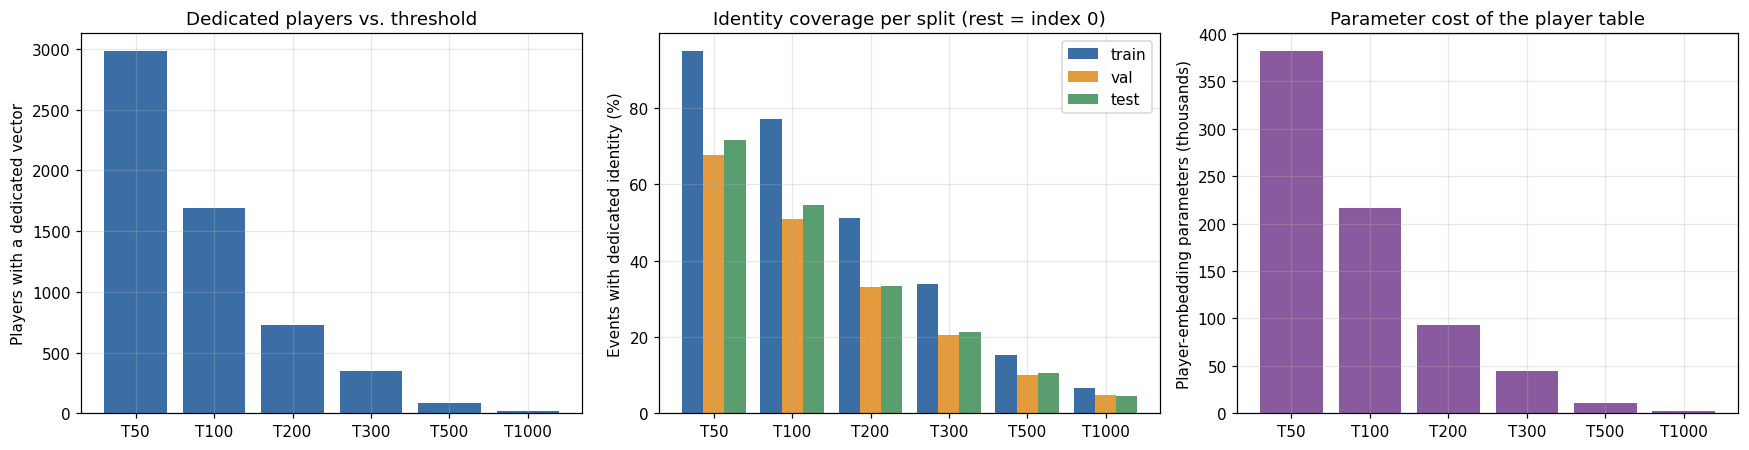

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
x_positions = np.arange(len(threshold_table))
labels = [f"T{t}" for t in threshold_table.index]

axes[0].bar(x_positions, threshold_table["dedicated embeddings"], color="#3b6ea5")
axes[0].set_xticks(x_positions)
axes[0].set_xticklabels(labels)
axes[0].set_ylabel("Players with a dedicated vector")
axes[0].set_title("Dedicated players vs. threshold")

width = 0.27
for offset, split_name, colour in [(-width, "train", "#3b6ea5"), (0, "val", "#e39b3b"), (width, "test", "#5a9e6f")]:
    axes[1].bar(x_positions + offset, threshold_table[f"{split_name} % dedicated"], width=width, color=colour, label=split_name)
axes[1].set_xticks(x_positions)
axes[1].set_xticklabels(labels)
axes[1].set_ylabel("Events with dedicated identity (%)")
axes[1].set_title("Identity coverage per split (rest = index 0)")
axes[1].legend()

axes[2].bar(x_positions, threshold_table["player-embedding parameters"] / 1000, color="#8a5a9e")
axes[2].set_xticks(x_positions)
axes[2].set_xticklabels(labels)
axes[2].set_ylabel("Player-embedding parameters (thousands)")
axes[2].set_title("Parameter cost of the player table")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_threshold_tradeoff.png", bbox_inches="tight")
plt.show()

**What the figure shows.** Three views of the same threshold choice: number of dedicated players, share of events keeping identity per split, and parameters spent on the player table.

**What it shows.** Moving from T300 to T100 roughly doubles identity coverage in every split and multiplies the player table by almost five. Held-out coverage is consistently below training coverage.

**What it means.** T100 is a large change to the model's input, not a small tweak — which is why it is tested against both T300 and a shuffled control rather than adopted on coverage alone.

**What cannot be concluded.** Nothing here indicates which threshold predicts better.

## 4. Building the encodings

An *encoding* is the complete mapping from raw ids to model indices: player (threshold-dependent), team, role and competition (all built from training values only, with 0 = unseen). The functions below are added to `src/data.py`. Each encoding is saved with its vocabularies and the per-event player index, so it can be reproduced exactly.

In [7]:
%%writefile -a src/data.py

# ---------------------------------------------------------------------------
# Identity vocabularies and encodings (written by notebook 02)
# ---------------------------------------------------------------------------

def count_train_events_per_player(events):
    """Number of TRAINING events per player. Validation and test are never counted."""
    train_events = events[events["split"] == "train"]
    return train_events["player_id"].value_counts()


def build_player_vocabulary(train_counts, threshold):
    """Map player_id -> index for players with at least `threshold` training events.

    Indices start at 1. Index 0 is reserved for "no dedicated identity" (below threshold or
    unseen in training). Players are ordered by training count (then id) so the mapping is
    deterministic.
    """
    eligible = train_counts[train_counts >= threshold]
    table = pd.DataFrame({"player_id": eligible.index, "train_events": eligible.values})
    table = table.sort_values(["train_events", "player_id"], ascending=[False, True])
    vocabulary = {}
    next_index = 1
    for player_id in table["player_id"]:
        vocabulary[int(player_id)] = next_index
        next_index = next_index + 1
    return vocabulary


def build_train_vocabulary(events, column):
    """Map raw values of `column` seen in TRAIN to indices 1..n. Unseen values will get 0."""
    train_values = sorted(events.loc[events["split"] == "train", column].unique())
    vocabulary = {}
    for position, value in enumerate(train_values):
        vocabulary[int(value)] = position + 1
    return vocabulary


def map_to_index(values, vocabulary):
    """Apply a vocabulary; anything not in it becomes 0."""
    mapped = values.map(vocabulary)
    return mapped.fillna(0).astype("int64").to_numpy()


def shuffle_player_band(events, player_index, train_counts, band_low, band_high, seed,
                        cell_columns=("split", "position_id")):
    """T100-shuffled control.

    For players with band_low <= training events < band_high, the player index of their
    events is randomly permuted among all band events that share the same `cell_columns`
    (default: split and role). Players outside the band are untouched. The number of
    dedicated vectors and the number of events using each vector stay exactly the same;
    only the link between a vector and the specific player who acted is destroyed.
    """
    band_players = train_counts[(train_counts >= band_low) & (train_counts < band_high)].index
    in_band = events["player_id"].isin(band_players).to_numpy()
    shuffled_index = player_index.copy()
    rng = np.random.default_rng(seed)
    band_events = events[in_band]
    for _, cell in band_events.groupby(list(cell_columns), sort=True):
        rows = cell.index.to_numpy()
        values_in_cell = shuffled_index[rows]
        shuffled_index[rows] = rng.permutation(values_in_cell)
    return shuffled_index


def build_encoding(events, name, threshold, shuffle_band=None, shuffle_seed=None,
                   shuffle_cell=("split", "position_id")):
    """Build a complete identity encoding. Returns (encoding dict, per-event player index)."""
    train_counts = count_train_events_per_player(events)
    player_vocabulary = build_player_vocabulary(train_counts, threshold)
    player_index = map_to_index(events["player_id"], player_vocabulary)
    if shuffle_band is not None:
        player_index = shuffle_player_band(events, player_index, train_counts,
                                           shuffle_band[0], shuffle_band[1], shuffle_seed, shuffle_cell)
    encoding = {
        "name": name,
        "threshold": threshold,
        "shuffle_band": shuffle_band,
        "shuffle_seed": shuffle_seed,
        "shuffle_cell": list(shuffle_cell) if shuffle_band is not None else None,
        "n_events": int(len(events)),
        "player_vocabulary": {str(key): value for key, value in player_vocabulary.items()},
        "team_vocabulary": {str(key): value for key, value in build_train_vocabulary(events, "team_id").items()},
        "role_vocabulary": {str(key): value for key, value in build_train_vocabulary(events, "position_id").items()},
        "competition_vocabulary": {str(key): value for key, value in build_train_vocabulary(events, "competition_id").items()},
    }
    return encoding, player_index


def save_encoding(folder, encoding, player_index):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    with open(folder / "encoding.json", "w") as handle:
        json.dump(encoding, handle, indent=1)
    np.save(folder / "player_index.npy", player_index)


def load_encoding(folder):
    folder = Path(folder)
    with open(folder / "encoding.json") as handle:
        encoding = json.load(handle)
    encoding["player_index"] = np.load(folder / "player_index.npy")
    return encoding


# ---------------------------------------------------------------------------
# Model input features
# ---------------------------------------------------------------------------

# The 15 categorical inputs, in a fixed order.
CATEGORICAL_FEATURES = [
    "player", "team", "role", "competition",                           # identity
    "zone",                                                            # space
    "period", "minute_bin",                                            # time
    "score_diff", "poss_len", "possession_flag",       # game state
    "prev_action", "prev_outcome", "prev_end_zone", "same_player_as_prev",  # history
]
# The 4 continuous inputs.
CONTINUOUS_FEATURES = ["x_norm", "y_norm", "dt", "t_poss"]

# Which source column provides each possession feature (see notebook 01, Section 8.1).
POSSESSION_SOURCE_COLUMNS = {
    "pre_action": {"play_pattern": "prev_play_pattern_id", "poss_len": "prev_poss_len",
                   "possession_flag": "team_change", "t_poss": "t_poss_prev"},
    "original":   {"play_pattern": "play_pattern_id", "poss_len": "poss_len",
                   "possession_flag": "new_possession", "t_poss": "t_poss"},
}


def encode_features(events, encoding, possession_features="pre_action"):
    """Turn the event table into model inputs.

    Returns (features, vocabulary_sizes):
      features          dict name -> numpy array with one value per event
      vocabulary_sizes  dict categorical name -> number of rows its embedding table needs
    """
    source = POSSESSION_SOURCE_COLUMNS[possession_features]
    features = {}

    # identity (index 0 = no dedicated identity / unseen in training)
    features["player"] = encoding["player_index"].astype("int64")
    team_vocabulary = {int(key): value for key, value in encoding["team_vocabulary"].items()}
    role_vocabulary = {int(key): value for key, value in encoding["role_vocabulary"].items()}
    competition_vocabulary = {int(key): value for key, value in encoding["competition_vocabulary"].items()}
    features["team"] = map_to_index(events["team_id"], team_vocabulary)
    features["role"] = map_to_index(events["position_id"], role_vocabulary)
    features["competition"] = map_to_index(events["competition_id"], competition_vocabulary)

    # context
    features["zone"] = events["zone"].to_numpy().astype("int64")
    features["period"] = events["period"].to_numpy().astype("int64")
    features["minute_bin"] = events["minute_bin"].to_numpy().astype("int64")
    features["score_diff"] = events["score_diff_idx"].to_numpy().astype("int64")
    features["play_pattern"] = events[source["play_pattern"]].to_numpy().astype("int64")
    features["poss_len"] = events[source["poss_len"]].to_numpy().astype("int64")
    features["possession_flag"] = events[source["possession_flag"]].to_numpy().astype("int64")
    features["prev_action"] = events["prev_action_id"].to_numpy().astype("int64")
    features["prev_outcome"] = events["prev_outcome"].to_numpy().astype("int64")
    features["prev_end_zone"] = events["prev_end_zone"].to_numpy().astype("int64")
    features["same_player_as_prev"] = events["same_player_as_prev"].to_numpy().astype("int64")

    features["x_norm"] = events["x_norm"].to_numpy().astype("float32")
    features["y_norm"] = events["y_norm"].to_numpy().astype("float32")
    features["dt"] = events["dt"].to_numpy().astype("float32")
    features["t_poss"] = events[source["t_poss"]].to_numpy().astype("float32")

    vocabulary_sizes = {
        "player": len(encoding["player_vocabulary"]) + 1,
        "team": len(encoding["team_vocabulary"]) + 1,
        "role": len(encoding["role_vocabulary"]) + 1,
        "competition": len(encoding["competition_vocabulary"]) + 1,
        "zone": 96,
        "period": 5,            # codes 1-4 (0 unused)
        "minute_bin": 24,
        "score_diff": 7,
        "play_pattern": 10,     # codes 1-9, 0 = no previous event
        "poss_len": 22,         # 0-20, 21 = no previous event
        "possession_flag": 2,
        "prev_action": 16,      # 15 action classes + END
        "prev_outcome": 3,
        "prev_end_zone": 96,
        "same_player_as_prev": 2,
    }
    return features, vocabulary_sizes

Appending to src/data.py


In [8]:
importlib.reload(data)
ENCODINGS_DIR = ARTIFACTS_DIR / "encodings"
SHUFFLE_SEED = 20260918          # fixed once; recorded in the encoding file

encoding_specs = [
    {"name": "T300", "threshold": 300, "shuffle_band": None, "shuffle_seed": None},
    {"name": "T100", "threshold": 100, "shuffle_band": None, "shuffle_seed": None},
    {"name": "T100_shuffled", "threshold": 100, "shuffle_band": [100, 300], "shuffle_seed": SHUFFLE_SEED},
]
built_encodings = {}
for spec in encoding_specs:
    encoding, player_index = data.build_encoding(events, spec["name"], spec["threshold"],
                                                 spec["shuffle_band"], spec["shuffle_seed"])
    data.save_encoding(ENCODINGS_DIR / spec["name"], encoding, player_index)
    built_encodings[spec["name"]] = player_index
    print(f"{spec['name']:14s} dedicated players: {len(encoding['player_vocabulary']):5d} | "
          f"events with index > 0: {(player_index > 0).mean() * 100:.2f}%")

T300           dedicated players:   350 | events with index > 0: 31.18%
T100           dedicated players:  1691 | events with index > 0: 72.13%
T100_shuffled  dedicated players:  1691 | events with index > 0: 72.13%


### 4.1 Checking the shuffled control — and a correction to its definition

The control is only meaningful if (a) it leaves everything outside the band untouched, (b) it keeps the same number of events per vector, and (c) it actually changes the player behind most band events. A permutation cannot change anything inside a cell that contains only one band player, so (c) is **measured** for three possible cell definitions:

* **split × role × team** — the definition initially planned;
* **split × role × competition**;
* **split × role** — the definition finally used.

In [9]:
index_T100 = built_encodings["T100"]
index_shuffled = built_encodings["T100_shuffled"]
band_players = train_counts[(train_counts >= 100) & (train_counts < 300)].index
in_band = events["player_id"].isin(band_players).to_numpy()

definition_rows = []
for cell_columns in [("split", "position_id", "team_id"), ("split", "position_id", "competition_id"), ("split", "position_id")]:
    candidate = data.shuffle_player_band(events, index_T100, train_counts, 100, 300, SHUFFLE_SEED, cell_columns)
    row = {"cell definition": " x ".join(cell_columns)}
    train_band_cells = events[in_band & (events["split"] == "train").to_numpy()].groupby(list(cell_columns[1:]))
    row["median band players per cell (train)"] = float(train_band_cells["player_id"].nunique().median())
    for split_name in ["train", "val", "test"]:
        split_band = in_band & (events["split"] == split_name).to_numpy()
        row[f"{split_name}: player changed (%)"] = round(100 * (candidate[split_band] != index_T100[split_band]).mean(), 1)
    definition_rows.append(row)
print("Share of band events whose player index is changed by the permutation, per cell definition:")
display(pd.DataFrame(definition_rows).set_index("cell definition"))
print("\nChecks of the final T100-shuffled encoding (cell = split x role):")

shuffle_checks = {
    "events outside the band changed": int((index_T100[~in_band] != index_shuffled[~in_band]).sum()),
    "events per index identical (all splits)": bool(np.array_equal(np.bincount(index_T100, minlength=2000),
                                                                   np.bincount(index_shuffled, minlength=2000))),
    "band players": int(len(band_players)),
    "band events": int(in_band.sum()),
}
for split_name in ["train", "val", "test"]:
    split_band = in_band & (events["split"] == split_name).to_numpy()
    changed = index_T100[split_band] != index_shuffled[split_band]
    shuffle_checks[f"{split_name}: band events whose player index changed (%)"] = round(100 * changed.mean(), 2)
pd.Series(shuffle_checks).to_frame("value")

Share of band events whose player index is changed by the permutation, per cell definition:


,median band players per cell (train),train: player changed (%),val: player changed (%),test: player changed (%)
cell definition,,,,
split x position_id x team_id,1.0,24.4,9.4,6.6
split x position_id x competition_id,6.0,85.3,46.9,51.7
split x position_id,124.0,98.8,91.0,93.0



Checks of the final T100-shuffled encoding (cell = split x role):


,value
events outside the band changed,0
events per index identical (all splits),True
band players,1341
band events,269813
train: band events whose player index changed (%),98.79
val: band events whose player index changed (%),90.99
test: band events whose player index changed (%),93.04


**Problem found.** Under the approved definition (split × role × team), only about a quarter of training band events — and fewer than one in ten validation/test band events — actually receive another player's index. A typical team has only **one** band player in a given role, so the permutation has nothing to swap. A model trained on that "shuffled" encoding would still see the true player behind ~75% of band events, and a T100 vs. T100-shuffled comparison would be nearly meaningless.

**Why it matters.** The control exists to remove player-specific information while keeping everything else. A control that keeps three quarters of the information it is meant to remove cannot support the conclusion it is designed for.

**Smallest defensible correction.** Drop team (and competition) from the cell and permute within **split × role**. Team and competition each have their own input vector, so the model still receives that information directly; what is removed is only the player-specific part (and whatever team information was duplicated inside the player vector). Role is kept fixed, so a band player's vector still receives only events from players in the same role. With this definition the player index changes for about 99% of training band events.

The cell definition therefore differs from the one initially planned (split × role × team). The research question, the band (100–299 events) and the decision rule are unchanged.

The cell below verifies the final encoding.

**RESULT.** In the final T100-shuffled encoding, events outside the band are untouched, every vector is used by exactly as many events as in T100, and the player behind almost every training band event has changed.

**INTERPRETATION.** A band vector in T100-shuffled is trained on a random mix of band players with the same role, so it can learn role-level behaviour but not an individual's habits.

**LIMITATION.** A small share of events keeps its original index by chance (a permutation can leave an item in place). This makes the control slightly conservative: any T100 vs. T100-shuffled difference slightly *under*-estimates the value of player-specific information.

## 5. Evaluation metrics

All models in Track A are compared with the same metrics, computed on the same events (every event scored once; see notebook 01, Section 6.2). Definitions:

| Metric | What it is | Why it is reported |
|---|---|---|
| **Logits** | The model's raw score for each of the 15 classes; higher = more likely. | Every probability is derived from them. |
| **Softmax** | Turns logits into probabilities that are positive and sum to 1: p = exp(logit) / Σ exp(logits). | |
| **NLL (negative log-likelihood)** | Average of −log p(true action). 0 is perfect; predicting all 15 classes equally gives ln 15 ≈ 2.708. Also called **cross-entropy**. | The main metric. It rewards putting high probability on the right answer and punishes confident mistakes. The later mechanistic analysis works with log-probabilities directly, so they must be good. |
| **Accuracy** | Share of events whose most probable class is the true one. | Easy to read, but dominated by common classes. |
| **Top-k accuracy** | Share of events whose true class is among the k most probable. | Shows whether the right action is at least a close candidate. |
| **F1 (per class)** | Harmonic mean of precision (when the model predicts class c, how often is it right?) and recall (of all true class-c events, how many did it find?). | Shows performance on each class separately, including rare ones. |
| **Macro-F1** | The unweighted average of the 15 per-class F1 scores. | Every class counts equally, so ignoring rare classes is penalised. |
| **ECE (expected calibration error)** | Events are grouped by the model's confidence in its top prediction (15 equal-width bins). In each bin, confidence is compared with actual accuracy; ECE is the weighted average gap. 0 = perfectly calibrated. | A calibrated model's "70%" really means right 70% of the time. The later analysis interprets probabilities, so calibration matters. |
| **Match-level bootstrap CI** | Resample whole **matches** with replacement many times, recompute the metric each time, and take the 2.5th and 97.5th percentiles as a 95% confidence interval. | Events in the same match are not independent, so matches, not events, are resampled. |

In [10]:
%%writefile src/metrics.py
"""
src/metrics.py — evaluation metrics shared by every Track A model.
Written by notebook 02. All functions take numpy arrays.
"""
import numpy as np
from sklearn.metrics import f1_score, confusion_matrix

NUM_CLASSES = 15


def log_softmax(logits):
    """Convert logits [n, 15] into log-probabilities, in a numerically stable way."""
    largest = logits.max(axis=1, keepdims=True)
    shifted = logits - largest
    log_normaliser = np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    return shifted - log_normaliser


def per_event_nll(logits, targets):
    """-log p(true class) for every event."""
    log_probabilities = log_softmax(logits)
    event_numbers = np.arange(len(targets))
    return -log_probabilities[event_numbers, targets]


def top_k_accuracy(logits, targets, k):
    """Share of events whose true class is among the k highest logits."""
    order = np.argsort(-logits, axis=1)
    top_k = order[:, :k]
    hits = (top_k == targets[:, None]).any(axis=1)
    return float(hits.mean())


def expected_calibration_error(probabilities, targets, n_bins=15):
    """Top-label ECE with equal-width confidence bins."""
    confidence = probabilities.max(axis=1)
    predicted = probabilities.argmax(axis=1)
    correct = (predicted == targets).astype(float)
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for bin_number in range(n_bins):
        low = bin_edges[bin_number]
        high = bin_edges[bin_number + 1]
        if bin_number == 0:
            in_bin = (confidence >= low) & (confidence <= high)
        else:
            in_bin = (confidence > low) & (confidence <= high)
        if in_bin.sum() == 0:
            continue
        gap = abs(correct[in_bin].mean() - confidence[in_bin].mean())
        ece += (in_bin.sum() / len(targets)) * gap
    return float(ece)


def reliability_table(probabilities, targets, n_bins=15):
    """Per-bin mean confidence, accuracy and count (used for reliability diagrams)."""
    confidence = probabilities.max(axis=1)
    correct = (probabilities.argmax(axis=1) == targets).astype(float)
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    rows = []
    for bin_number in range(n_bins):
        low = bin_edges[bin_number]
        high = bin_edges[bin_number + 1]
        in_bin = (confidence > low) & (confidence <= high)
        if bin_number == 0:
            in_bin = (confidence >= low) & (confidence <= high)
        count = int(in_bin.sum())
        if count == 0:
            rows.append({"bin_low": low, "bin_high": high, "count": 0,
                         "mean_confidence": np.nan, "accuracy": np.nan})
        else:
            rows.append({"bin_low": low, "bin_high": high, "count": count,
                         "mean_confidence": float(confidence[in_bin].mean()),
                         "accuracy": float(correct[in_bin].mean())})
    return rows


def compute_metrics(logits, targets):
    """All headline metrics for one set of predictions."""
    log_probabilities = log_softmax(logits)
    probabilities = np.exp(log_probabilities)
    predicted = logits.argmax(axis=1)
    nll_values = -log_probabilities[np.arange(len(targets)), targets]
    per_class = f1_score(targets, predicted, labels=list(range(NUM_CLASSES)), average=None, zero_division=0)
    return {
        "n_events": int(len(targets)),
        "nll": float(nll_values.mean()),
        "accuracy": float((predicted == targets).mean()),
        "top3_accuracy": top_k_accuracy(logits, targets, 3),
        "top5_accuracy": top_k_accuracy(logits, targets, 5),
        "macro_f1": float(per_class.mean()),
        "per_class_f1": [float(value) for value in per_class],
        "ece": expected_calibration_error(probabilities, targets),
    }


def confusion(logits, targets):
    """Confusion matrix: rows = true class, columns = predicted class."""
    return confusion_matrix(targets, logits.argmax(axis=1), labels=list(range(NUM_CLASSES)))


def match_bootstrap_mean(values, match_ids, n_resamples=2000, seed=0):
    """Mean of per-event `values` with a 95% CI from resampling whole matches.

    For each resample, matches are drawn with replacement; the statistic is
    (sum of values in drawn matches) / (number of events in drawn matches).
    """
    unique_matches, match_position = np.unique(match_ids, return_inverse=True)
    n_matches = len(unique_matches)
    sum_per_match = np.bincount(match_position, weights=values, minlength=n_matches)
    count_per_match = np.bincount(match_position, minlength=n_matches).astype(float)
    rng = np.random.default_rng(seed)
    resampled_means = np.empty(n_resamples)
    for resample in range(n_resamples):
        drawn = rng.integers(0, n_matches, size=n_matches)
        resampled_means[resample] = sum_per_match[drawn].sum() / count_per_match[drawn].sum()
    point = float(values.mean())
    return {"mean": point,
            "ci_low": float(np.percentile(resampled_means, 2.5)),
            "ci_high": float(np.percentile(resampled_means, 97.5))}


def match_bootstrap_macro_f1(logits, targets, match_ids, n_resamples=500, seed=0):
    """Macro-F1 with a 95% CI from resampling whole matches."""
    predicted = logits.argmax(axis=1)
    unique_matches, match_position = np.unique(match_ids, return_inverse=True)
    rows_per_match = []
    for match_number in range(len(unique_matches)):
        rows_per_match.append(np.where(match_position == match_number)[0])
    rng = np.random.default_rng(seed)
    values = np.empty(n_resamples)
    for resample in range(n_resamples):
        drawn = rng.integers(0, len(unique_matches), size=len(unique_matches))
        rows = np.concatenate([rows_per_match[m] for m in drawn])
        values[resample] = f1_score(targets[rows], predicted[rows], labels=list(range(NUM_CLASSES)),
                                    average="macro", zero_division=0)
    point = f1_score(targets, predicted, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)
    return {"mean": float(point),
            "ci_low": float(np.percentile(values, 2.5)),
            "ci_high": float(np.percentile(values, 97.5))}

Overwriting src/metrics.py


In [11]:
import src.metrics as metrics
importlib.reload(metrics)

# Sanity checks of the metric code on tiny hand-made examples.
uniform_logits = np.zeros((4, 15))
targets_example = np.array([0, 1, 2, 3])
assert abs(metrics.compute_metrics(uniform_logits, targets_example)["nll"] - np.log(15)) < 1e-9
perfect_logits = np.full((4, 15), -50.0)
perfect_logits[np.arange(4), targets_example] = 50.0
perfect = metrics.compute_metrics(perfect_logits, targets_example)
assert perfect["accuracy"] == 1.0 and perfect["nll"] < 1e-9 and perfect["ece"] < 1e-9
print("Metric sanity checks passed: uniform NLL = ln 15, perfect predictions give NLL 0, accuracy 1, ECE 0.")

Metric sanity checks passed: uniform NLL = ln 15, perfect predictions give NLL 0, accuracy 1, ECE 0.


## 6. Non-neural baselines

A **baseline** is a simpler model that answers "how much can be achieved without X?". The Transformer is only of interest if it beats them beyond noise.

| Baseline | Input | Question it answers |
|---|---|---|
| **B1a Class prior** | nothing | What does always predicting the overall class frequencies achieve? The trivial floor. |
| **B1b Zone prior** | start zone | How much does location alone explain? |
| **B2 Markov** | previous action × zone | How much comes from "what just happened, and where"? A *Markov* model predicts only from the immediately preceding state. |
| **B3 Logistic regression** | all 19 inputs of the current event (no attention over earlier events) | Is a sequence model needed at all, or do the current event's features suffice? *Logistic regression* is a linear model: each input value adds a fixed amount to each class's logit. |

Two further baselines need neural training and are fitted with the same training code as the Transformer: **B4** (an MLP over the current and three previous events, notebook 04) and the identity/context-restricted Transformers **B5–B7** (notebook 06).

**Smoothing (B1b, B2).** A count-based model can see a (previous action, zone) combination only a few times. *Additive smoothing* blends the observed frequencies with a coarser estimate: P(a | prev, zone) = (count(prev, zone, a) + α · P(a | zone)) / (count(prev, zone) + α). The strength α is chosen on **validation** NLL from {0.1, 1, 10, 100}; this is hyperparameter selection, which is what the validation split is for.

In [12]:
%%writefile src/baselines.py
"""
src/baselines.py — non-neural baselines B1-B3 (written by notebook 02).
Every function fits on training rows only and returns logits (log-probabilities) for
the rows it is asked to predict, so all models share one evaluation path.
"""
from pathlib import Path

import joblib
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy import sparse

NUM_CLASSES = 15


def class_prior(train_targets):
    counts = np.bincount(train_targets, minlength=NUM_CLASSES).astype(float)
    return counts / counts.sum()


def predict_class_prior(train_targets, n_rows):
    """B1a: every event gets the overall training class distribution."""
    prior = class_prior(train_targets)
    return np.tile(np.log(prior), (n_rows, 1))


def smoothed_conditional(train_keys, train_targets, n_keys, fallback, alpha):
    """P(action | key) with additive smoothing towards `fallback` [n_keys, 15] probabilities."""
    counts = np.zeros((n_keys, NUM_CLASSES))
    np.add.at(counts, (train_keys, train_targets), 1.0)
    totals = counts.sum(axis=1, keepdims=True)
    return (counts + alpha * fallback) / (totals + alpha)


def zone_prior_table(train_zone, train_targets, alpha):
    prior = class_prior(train_targets)
    fallback = np.tile(prior, (96, 1))
    return smoothed_conditional(train_zone, train_targets, 96, fallback, alpha)


def predict_zone_prior(train_zone, train_targets, zone, alpha):
    """B1b: P(action | start zone)."""
    table = zone_prior_table(train_zone, train_targets, alpha)
    return np.log(table[zone])


def predict_markov(train_prev_action, train_zone, train_targets, prev_action, zone, alpha):
    """B2: P(action | previous action, zone), smoothed towards P(action | zone)."""
    zone_table = zone_prior_table(train_zone, train_targets, alpha)
    n_keys = 16 * 96
    train_keys = train_prev_action * 96 + train_zone
    fallback = np.zeros((n_keys, NUM_CLASSES))
    for key in range(n_keys):
        fallback[key] = zone_table[key % 96]
    table = smoothed_conditional(train_keys, train_targets, n_keys, fallback, alpha)
    keys = prev_action * 96 + zone
    return np.log(table[keys])


def logistic_regression_design(features, categorical_names, continuous_names, rows, encoder=None, scaler=None):
    """One-hot categorical columns + standardised continuous columns (fitted on train only)."""
    categorical = np.stack([features[name][rows] for name in categorical_names], axis=1)
    continuous = np.stack([features[name][rows] for name in continuous_names], axis=1).astype(float)
    if encoder is None:
        encoder = OneHotEncoder(handle_unknown="ignore")
        encoder.fit(categorical)
        scaler = StandardScaler()
        scaler.fit(continuous)
    design = sparse.hstack([encoder.transform(categorical), sparse.csr_matrix(scaler.transform(continuous))]).tocsr()
    return design, encoder, scaler


def fit_logistic_regression(features, targets, categorical_names, continuous_names, train_rows,
                            max_iter=1000, C=1.0, chunk_iterations=200, checkpoint_path=None):
    """B3: multinomial logistic regression on the current event's inputs.

    Fitted with L-BFGS in chunks of `chunk_iterations` iterations. Each chunk starts from the
    coefficients of the previous one (warm start). After every chunk the model is saved to
    `checkpoint_path`, so an interrupted fit (e.g. a Colab disconnection) resumes where it
    stopped. Fitting stops when a chunk converges before its limit, or after `max_iter` in total.
    """
    design, encoder, scaler = logistic_regression_design(features, categorical_names, continuous_names, train_rows)
    train_targets = targets[train_rows]
    model = LogisticRegression(C=C, max_iter=chunk_iterations, warm_start=True)
    state = {"iterations_done": 0, "converged": False, "n_train_rows": int(len(train_rows))}
    if checkpoint_path is not None and Path(checkpoint_path).exists():
        saved = joblib.load(checkpoint_path)
        if saved["state"]["n_train_rows"] == len(train_rows):
            model = saved["model"]
            state = saved["state"]
    while (not state["converged"]) and state["iterations_done"] < max_iter:
        model.fit(design, train_targets)
        used = int(model.n_iter_[0])
        state["iterations_done"] += used
        if used < chunk_iterations:
            state["converged"] = True
        if checkpoint_path is not None:
            Path(checkpoint_path).parent.mkdir(parents=True, exist_ok=True)
            joblib.dump({"model": model, "state": state}, checkpoint_path)
    return {"model": model, "encoder": encoder, "scaler": scaler,
            "categorical_names": categorical_names, "continuous_names": continuous_names,
            "iterations": state["iterations_done"], "converged": state["converged"]}


def predict_logistic_regression(fitted, features, rows):
    design, _, _ = logistic_regression_design(features, fitted["categorical_names"], fitted["continuous_names"],
                                              rows, fitted["encoder"], fitted["scaler"])
    log_probabilities = fitted["model"].predict_log_proba(design)
    # predict_log_proba only returns columns for classes seen in training; all 15 are present.
    return log_probabilities

Writing src/baselines.py


In [13]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # convergence is checked and printed explicitly below
import src.baselines as baselines
importlib.reload(baselines)

BASE_ENCODING = "T100"   # the encoding used during development (notebooks 02-04)
encoding = data.load_encoding(ENCODINGS_DIR / BASE_ENCODING)
features, vocabulary_sizes = data.encode_features(events, encoding, possession_features="pre_action")

targets = events["action_id"].to_numpy().astype("int64")
match_ids = events["match_id"].to_numpy()
train_rows = np.where(events["split"] == "train")[0]
val_rows = np.where(events["split"] == "val")[0]
train_targets = targets[train_rows]
val_targets = targets[val_rows]
print("Train events:", len(train_rows), "| validation events:", len(val_rows))

Train events: 525893 | validation events: 68003


In [14]:
baseline_logits = {}
alpha_search = {}

baseline_logits["B1a class prior"] = baselines.predict_class_prior(train_targets, len(val_rows))

for alpha in [0.1, 1.0, 10.0, 100.0]:
    logits = baselines.predict_zone_prior(features["zone"][train_rows], train_targets, features["zone"][val_rows], alpha)
    alpha_search[("B1b zone prior", alpha)] = metrics.per_event_nll(logits, val_targets).mean()
    logits = baselines.predict_markov(features["prev_action"][train_rows], features["zone"][train_rows], train_targets,
                                      features["prev_action"][val_rows], features["zone"][val_rows], alpha)
    alpha_search[("B2 Markov", alpha)] = metrics.per_event_nll(logits, val_targets).mean()

alpha_table = pd.Series(alpha_search).unstack(0).round(4)
alpha_table.index.name = "alpha"
best_alpha = alpha_table.idxmin()
print("Validation NLL for each smoothing strength (lower is better):")
print(alpha_table)
print("\nSelected alpha:", best_alpha.to_dict())

baseline_logits["B1b zone prior"] = baselines.predict_zone_prior(features["zone"][train_rows], train_targets,
                                                                 features["zone"][val_rows], best_alpha["B1b zone prior"])
baseline_logits["B2 Markov (prev action x zone)"] = baselines.predict_markov(
    features["prev_action"][train_rows], features["zone"][train_rows], train_targets,
    features["prev_action"][val_rows], features["zone"][val_rows], best_alpha["B2 Markov"])

Validation NLL for each smoothing strength (lower is better):
       B1b zone prior  B2 Markov
alpha                           
0.1            1.7821     1.4174
1.0            1.7820     1.4121
10.0           1.7818     1.4109
100.0          1.7824     1.4430

Selected alpha: {'B1b zone prior': 10.0, 'B2 Markov': 10.0}


**How the smoothing strength behaves.** Validation NLL changes only slightly across α: the training set is large, so most (previous action, zone) combinations are seen many times and smoothing matters only for rare ones. The selected α values are recorded and reused whenever these baselines are refitted.

### 6.1 Logistic regression (B3) and the size of the possession correction

B3 is fitted twice: once with the **pre-action** possession features (the corrected encoding used everywhere in Track A) and once with the **original** possession features. The difference in validation NLL gives a first, model-based estimate of how much predictive signal the original features contained that is not available before the action (see notebook 01, Section 8.1). This is a measurement of the audit finding, not a model-selection step. The regularisation strength C = 1.0 is an engineering value (the training set is large, so the model is only weakly regularised); it is not tuned. The optimiser is allowed up to 1,000 L-BFGS iterations in total, run in chunks of 200 that continue from the previous coefficients; whether it converged is printed.

In [15]:
lr_runtime = {}
for possession_mode in ["pre_action", "original"]:
    mode_features, _ = data.encode_features(events, encoding, possession_features=possession_mode)
    start_time = time.time()
    checkpoint_path = ARTIFACTS_DIR / "b3_checkpoints" / f"{BASE_ENCODING}_{possession_mode}.joblib"
    fitted = baselines.fit_logistic_regression(mode_features, targets, data.CATEGORICAL_FEATURES,
                                               data.CONTINUOUS_FEATURES, train_rows, max_iter=1000,
                                               checkpoint_path=checkpoint_path)
    lr_runtime[possession_mode] = time.time() - start_time
    label = "B3 logistic regression" if possession_mode == "pre_action" else "B3 logistic regression [original possession features]"
    baseline_logits[label] = baselines.predict_logistic_regression(fitted, mode_features, val_rows)
    print(f"{label}: total L-BFGS iterations {fitted['iterations']} | converged: {fitted['converged']} "
          f"| time in this session {lr_runtime[possession_mode]:.0f} s")

B3 logistic regression: total L-BFGS iterations 477 | converged: True | time in this session 278 s
B3 logistic regression [original possession features]: total L-BFGS iterations 528 | converged: True | time in this session 258 s


In [16]:
result_rows = []
for name, logits in baseline_logits.items():
    summary = metrics.compute_metrics(logits, val_targets)
    nll_ci = metrics.match_bootstrap_mean(metrics.per_event_nll(logits, val_targets), match_ids[val_rows], n_resamples=2000, seed=0)
    result_rows.append({"baseline": name,
                        "val NLL": round(summary["nll"], 4),
                        "NLL 95% CI": f"[{nll_ci['ci_low']:.4f}, {nll_ci['ci_high']:.4f}]",
                        "accuracy": round(summary["accuracy"], 4),
                        "top-3 acc.": round(summary["top3_accuracy"], 4),
                        "macro-F1": round(summary["macro_f1"], 4),
                        "ECE": round(summary["ece"], 4)})
baseline_table = pd.DataFrame(result_rows).set_index("baseline")
baseline_table

,val NLL,NLL 95% CI,accuracy,top-3 acc.,macro-F1,ECE
baseline,,,,,,
B1a class prior,1.9746,"[1.9483, 2.0024]",0.3208,0.7351,0.0324,0.0185
B1b zone prior,1.7818,"[1.7590, 1.8052]",0.3419,0.7637,0.1353,0.0140
B2 Markov (prev action x zone),1.4109,"[1.3929, 1.4282]",0.4537,0.8508,0.3588,0.0118
B3 logistic regression,1.0522,"[1.0384, 1.0650]",0.5786,0.9264,0.5085,0.0121
B3 logistic regression [original possession features],1.0496,"[1.0366, 1.0615]",0.5810,0.9252,0.5143,0.0125


In [17]:
leak_difference = (metrics.per_event_nll(baseline_logits["B3 logistic regression [original possession features]"], val_targets)
                   - metrics.per_event_nll(baseline_logits["B3 logistic regression"], val_targets))
leak_ci = metrics.match_bootstrap_mean(leak_difference, match_ids[val_rows], n_resamples=2000, seed=1)
print("Paired difference in validation NLL, original minus pre-action possession features:")
print(f"  {leak_ci['mean']:.4f} nats  (95% match-bootstrap CI {leak_ci['ci_low']:.4f} to {leak_ci['ci_high']:.4f})")
print("  Negative = the original (partly post-action) features predict better.")

Paired difference in validation NLL, original minus pre-action possession features:
  -0.0026 nats  (95% match-bootstrap CI -0.0054 to 0.0003)
  Negative = the original (partly post-action) features predict better.


**RESULT.** The table gives validation performance for each non-neural baseline, with 95% confidence intervals from resampling matches.

**OBSERVATION.** Each added source of information lowers validation NLL: class frequencies 1.9746 → start zone 1.7818 → previous action × zone 1.4109 → all current-event features (logistic regression) 1.0522 nats. Accuracy rises from 32.1% to 57.9% and macro-F1 from 0.032 to 0.509 along the same ladder. With the original possession features, logistic regression reaches 1.0496 nats; the paired difference is −0.0026 nats (95% CI −0.0054 to +0.0003).

**INTERPRETATION.** The previous action and the full set of current-event features carry most of the easily usable signal; location alone helps only modestly. For the possession features, the confidence interval of the paired difference includes zero, so a linear model on the current event does not show a clear predictive advantage from the original (partly post-action) features. The decision in notebook 01 does not rest on this number: it follows from the provenance evidence there (the original values depend on the type of the current action). The comparison shows only that the correction costs little predictive performance for this model class.

**SCIENTIFIC SIGNIFICANCE.** These numbers are the performance floor. The Transformer (and the MLP baseline B4) has to beat B3 by more than the confidence interval; otherwise attention over earlier events adds nothing that a linear model on the current event could not provide.

**LIMITATION.** The possession-feature difference is measured with a linear model; a Transformer may extract more or less from the same features, so the difference is not a measure of leakage in the Transformer. Test results for these baselines are reported only in notebook 06.

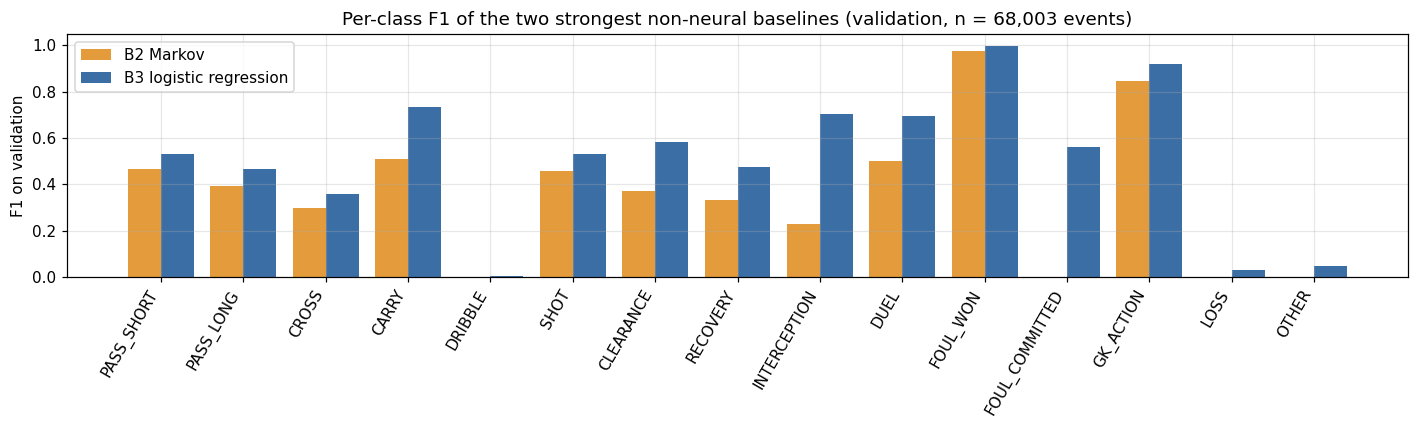

,B2 Markov (prev action x zone),B3 logistic regression
PASS_SHORT,0.468,0.529
PASS_LONG,0.392,0.467
CROSS,0.296,0.357
CARRY,0.510,0.732
DRIBBLE,0.000,0.003
SHOT,0.458,0.531
CLEARANCE,0.369,0.581
RECOVERY,0.332,0.474
INTERCEPTION,0.230,0.703
DUEL,0.502,0.697


In [18]:
per_class_rows = {}
for name in ["B2 Markov (prev action x zone)", "B3 logistic regression"]:
    per_class_rows[name] = metrics.compute_metrics(baseline_logits[name], val_targets)["per_class_f1"]
per_class_table = pd.DataFrame(per_class_rows, index=data.ACTION_NAMES).round(3)

fig, ax = plt.subplots(figsize=(13, 4))
positions = np.arange(len(data.ACTION_NAMES))
ax.bar(positions - 0.2, per_class_table.iloc[:, 0], width=0.4, label="B2 Markov", color="#e39b3b")
ax.bar(positions + 0.2, per_class_table.iloc[:, 1], width=0.4, label="B3 logistic regression", color="#3b6ea5")
ax.set_xticks(positions)
ax.set_xticklabels(data.ACTION_NAMES, rotation=60, ha="right")
ax.set_ylabel("F1 on validation")
ax.set_title(f"Per-class F1 of the two strongest non-neural baselines (validation, n = {len(val_rows):,} events)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_baseline_per_class_f1.png", bbox_inches="tight")
plt.show()
per_class_table

**What the figure shows.** F1 for every action class on validation, for the Markov baseline and logistic regression.

**What it shows.** Classes tied to a clear previous event score high even for the Markov model (FOUL_WON 0.98, GK_ACTION 0.85); see notebook 01, Section 8.2 for why FOUL_WON is nearly deterministic. Logistic regression adds most on defensive classes (INTERCEPTION 0.230 → 0.703, FOUL_COMMITTED 0.000 → 0.559, DUEL 0.502 → 0.697) and on CARRY (0.510 → 0.732). DRIBBLE (0.003), LOSS (0.030) and OTHER (0.045) remain essentially unpredicted, and CROSS stays low (0.357).

**What it means.** DRIBBLE, LOSS and CROSS are where a sequence model has room to improve; if the Transformer also leaves them near zero, that is reported as a class-coverage limitation. High F1 on FOUL_WON is an annotation effect and must not be read as modelling skill.

**What cannot be concluded.** Per-class F1 from a single baseline fit has no uncertainty estimate here; small differences between classes should not be over-read.

In [19]:
baseline_results = {
    "split": "val",
    "encoding": BASE_ENCODING,
    "possession_features": "pre_action (primary); original reported for the audit",
    "selected_alpha": best_alpha.to_dict(),
    "logistic_regression": {"C": 1.0, "max_iter": 1000},
    "table": baseline_table.reset_index().to_dict(orient="records"),
    "possession_feature_nll_difference_original_minus_pre_action": leak_ci,
}
with open(RESULTS_DIR / "baselines_validation.json", "w") as handle:
    json.dump(baseline_results, handle, indent=2)
print("Saved", RESULTS_DIR / "baselines_validation.json")

Saved /content/drive/MyDrive/soccer_mi/track_a/results/baselines_validation.json


## 7. Summary

* Under T100, 1,691 players receive a dedicated embedding and 77.0% of training events keep a player identity; under T300, 350 players and 33.8%. In validation and test the coverage is lower (about 51–55% under T100, 20–21% under T300), because held-out matches contain players who are rare or absent in training.
* The shuffled control permutes the player index within split × role and changes the player behind 98.8% of training band events.
* The strongest non-neural baseline is logistic regression on the current event (validation NLL 1.0522, accuracy 0.579, macro-F1 0.509). This is the floor for the neural models.
* With a linear model, the original possession features do not give a predictive advantage that is distinguishable from zero (−0.0026 nats, CI −0.0054 to +0.0003).
* The predictive comparison of T100, T300 and T100-shuffled is reported in notebook 05; test results for the baselines in notebook 06.